# Task 3 — Persistence features in the nonzero gate

Use the one new dataset, eda_spend_persistence_v2, and change only the occurrence classifier. Keep the positive-only CatBoost model, continuous CatBoost/LightGBM blend, gate threshold 0.5, and 80/20 mixture weight fixed. Compare on the same five development folds; the original holdout is a reused exploratory check. Analyze error groups here, during modeling. MAE is in THB, not official NMAE. Test is not used.

In [1]:
from pathlib import Path
import json,sys,joblib
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"src"/"pipeline"/"save_model.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.pipeline.random_seed import set_seed
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
from src.pipeline.read_evalutate_summarize import read_evaluation_index
from src.task3.models.spending_models import PositiveGate,WeightedPair
SEED=set_seed()
import numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from IPython.display import display
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from catboost import CatBoostClassifier
sns.set_theme(style="whitegrid")
SRC=ROOT/"src";TASK=SRC/"task3";SAVE=TASK/"save";RESULTS=TASK/"models"/"results"
DATA_NAME="eda_spend_persistence_v2";TARGET,ID="spending_30d","player_id"
card=json.loads((TASK/"data"/"eda"/f"{DATA_NAME}.json").read_text(encoding="utf-8"))
train=pd.read_parquet(SRC/card["splits"]["train"]["path"])
old_card=json.loads((TASK/"data"/"eda"/"eda_combined_v1.json").read_text(encoding="utf-8"))
old_train=pd.read_parquet(SRC/old_card["splits"]["train"]["path"])
assert train[ID].equals(old_train[ID]) and train[TARGET].equals(old_train[TARGET])
BASE=[c for c in old_train if c not in (ID,TARGET)]
PERSISTENCE=list(card["card"]["candidate_groups"]["persistence"])
assert len(BASE)==48 and len(PERSISTENCE)==4
FEATURES=BASE+PERSISTENCE
y=train[TARGET].astype(float)
bands=pd.cut(y,bins=[-1,0,100,1000,10000,50000,np.inf],labels=False)
dev_idx,valid_idx=train_test_split(np.arange(len(y)),test_size=.20,stratify=bands,random_state=SEED)
dev=train.iloc[dev_idx].reset_index(drop=True)
valid=train.iloc[valid_idx]
dev_bands=bands.iloc[dev_idx].reset_index(drop=True)
splits=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(dev,dev_bands))
old_model=joblib.load(SAVE/"t3_gate_blend_cv5_v2.joblib")
old_gate=old_model.first_model;old_blend=old_model.second_model
gate_weight=old_model.first_weight;gate_threshold=old_gate.threshold
cat_weight=old_blend.catboost_weight
assert gate_weight==.8 and gate_threshold==.5
print("Rows:",len(dev),len(valid),"features:",len(FEATURES))

Rows: 83200 20800 features: 52


## 1. Reconstruct the existing OOF reference

Read the saved fold predictions, with row alignment checks. This baseline is not refitted.

In [2]:
parts=[]
for fold,(_,check_pos) in enumerate(splits,1):
    gate=pd.read_parquet(RESULTS/f"round3_gate_fold{fold}_v1.parquet")
    blend=pd.read_parquet(RESULTS/f"round3_blend_fold{fold}_v1.parquet")
    assert gate.row_pos.tolist()==check_pos.tolist()==blend.row_pos.tolist()
    assert gate.true.equals(blend.true)
    amount=np.maximum(gate.positive_amount,0)
    continuous=np.maximum(cat_weight*blend.cat+(1-cat_weight)*blend.lgb,0)
    baseline_pred=gate_weight*np.where(gate.probability>=gate_threshold,amount,0)+(1-gate_weight)*continuous
    parts.append(pd.DataFrame({"fold":fold,"row_pos":check_pos,"true":gate.true,
        "old_probability":gate.probability,"old_amount":amount,
        "continuous":continuous,"baseline_prediction":baseline_pred}))
baseline=pd.concat(parts,ignore_index=True).sort_values("row_pos").reset_index(drop=True)
assert np.array_equal(baseline.row_pos,np.arange(len(dev)))
assert np.array_equal(baseline.true,dev[TARGET])
def fold_mae(values):
    frame=baseline[["fold","true"]].copy()
    frame["prediction"]=values
    return frame.groupby("fold").apply(lambda g:mean_absolute_error(g.true,g.prediction),include_groups=False)
base_scores=fold_mae(baseline.baseline_prediction)
assert abs(base_scores.mean()-2895.92)<.2
display(base_scores.rename("MAE_thb").to_frame().round(2))
print("Baseline mean:",round(base_scores.mean(),2))

,MAE_thb
fold,
1,2815.58
2,2973.69
3,2797.07
4,2929.51
5,2963.76


Baseline mean: 2895.92


## 2. Train, save, and evaluate the persistence-gate model

The new CatBoost classifier has the original settings, plus four deterministic persistence features. Preprocessing is fitted within each fold's training rows. Each fold prediction is cached with dataset lineage. The full-development classifier is saved inside a fitted PositiveGate and 80/20 mixture under a new name.

In [3]:
NAME="t3_gate_persistence_cv5_v4"
model_path,card_path,eval_path=(SAVE/f"{NAME}.joblib",SAVE/f"{NAME}.json",SAVE/f"{NAME}-evaluation.json")
NOMINAL=["primary_game","platform","seasonal_spending_pattern","segment"]
def classifier():
    numeric=[c for c in FEATURES if c not in NOMINAL]
    preprocess=ColumnTransformer([
        ("numeric",SimpleImputer(strategy="median",add_indicator=True),numeric),
        ("nominal",Pipeline([
            ("impute",SimpleImputer(strategy="constant",fill_value=-1)),
            ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),NOMINAL),
    ],remainder="drop",sparse_threshold=0)
    return Pipeline([("preprocess",preprocess),
        ("classifier",CatBoostClassifier(loss_function="Logloss",iterations=350,
            depth=6,learning_rate=.05,l2_leaf_reg=3.,random_seed=SEED,
            thread_count=4,verbose=False,allow_writing_files=False))])
key={"dataset":DATA_NAME,"dataset_created_at":card["created_at"],
     "seed":SEED,"features":FEATURES,"classifier":"CatBoost Logloss 350x6",
     "outer":"same five stratified development folds"}
fold_parts=[]
for fold,(fit_pos,check_pos) in enumerate(splits,1):
    path=RESULTS/f"{NAME}-fold{fold}.parquet"
    meta=RESULTS/f"{NAME}-fold{fold}.json"
    if path.exists()!=meta.exists():raise RuntimeError(f"Incomplete fold {fold}")
    if path.exists():
        assert json.loads(meta.read_text(encoding="utf-8"))=={"key":key,"fold":fold}
        part=pd.read_parquet(path)
        print("Loaded fold",fold)
    else:
        if model_path.exists() or card_path.exists() or eval_path.exists():
            raise RuntimeError("Saved model has missing fold cache")
        model=classifier()
        model.fit(dev.iloc[fit_pos][FEATURES],(dev.iloc[fit_pos][TARGET]>0).astype(int))
        p=model.predict_proba(dev.iloc[check_pos][FEATURES])[:,1]
        part=pd.DataFrame({"fold":fold,"row_pos":check_pos,
                           "true":dev.iloc[check_pos][TARGET].to_numpy(),"probability":p})
        RESULTS.mkdir(parents=True,exist_ok=True)
        part.to_parquet(path,index=False)
        meta.write_text(json.dumps({"key":key,"fold":fold},indent=2),encoding="utf-8")
        print("Trained fold",fold)
    assert part.row_pos.tolist()==check_pos.tolist()
    assert np.array_equal(part.true,dev.iloc[check_pos][TARGET])
    fold_parts.append(part)
new_oof=pd.concat(fold_parts,ignore_index=True).sort_values("row_pos").reset_index(drop=True)
assert np.array_equal(new_oof.row_pos,np.arange(len(dev)))
new_probability=new_oof.probability.to_numpy()
new_prediction=gate_weight*np.where(new_probability>=gate_threshold,baseline.old_amount,0)+(1-gate_weight)*baseline.continuous
new_scores=fold_mae(new_prediction)
if model_path.exists() and card_path.exists() and eval_path.exists():
    model=joblib.load(model_path)
    result=json.loads(eval_path.read_text(encoding="utf-8"))
    assert result["metric"]=="MAE_thb"
    print("Loaded saved model")
elif model_path.exists() or card_path.exists() or eval_path.exists():
    raise RuntimeError("Incomplete saved model")
else:
    occurrence=classifier()
    occurrence.fit(dev[FEATURES],(dev[TARGET]>0).astype(int))
    model=WeightedPair(PositiveGate(occurrence,old_gate.positive_amount_model,gate_threshold),
                       old_blend,gate_weight)
    holdout_pred=model.predict(valid.drop(columns=[ID,TARGET]))
    save_model(task=3,name=NAME,model=model,data_name=DATA_NAME,
        card={"idea":"Persistence features in nonzero gate only",
              "source_model":"t3_gate_blend_cv5_v2","new_features":PERSISTENCE,
              "unchanged_components":["positive-only CatBoost","continuous 40/60 blend"],
              "gate_threshold":gate_threshold,"gate_weight":gate_weight,
              "development_cv_mean_MAE_thb":float(new_scores.mean()),"seed":SEED,
              "metric_note":"MAE THB; NMAE denominator unavailable"})
    result=evaluate_model(task=3,name=NAME,score=mean_absolute_error(valid[TARGET],holdout_pred),
        metric_name="MAE_thb",higher_is_better=False,
        card={"split":"original stratified 20% holdout; reused",
              "development_fold_MAE_thb":new_scores.to_dict(),"seed":SEED})
    print("Saved model and evaluation")
holdout_mae=mean_absolute_error(valid[TARGET],model.predict(valid.drop(columns=[ID,TARGET])))
assert abs(holdout_mae-result["score"])<.05
display(pd.DataFrame({"baseline":base_scores,"gate_persistence":new_scores,
                      "delta":new_scores-base_scores}).round(2))
print("New mean CV:",round(new_scores.mean(),2),"delta:",round(new_scores.mean()-base_scores.mean(),2),
      "holdout:",round(holdout_mae,2))

Loaded fold 1
Loaded fold 2
Loaded fold 3
Loaded fold 4
Loaded fold 5
Loaded saved model


,baseline,gate_persistence,delta
fold,,,
1,2815.58,2815.27,-0.31
2,2973.69,2972.36,-1.33
3,2797.07,2798.82,1.75
4,2929.51,2928.82,-0.69
5,2963.76,2963.76,-0.00


New mean CV: 2895.81 delta: -0.12 holdout: 2845.08


## 3. Analyze what changed on the same OOF rows

Compare all rows, zero targets, positive targets, 50k+ spenders, and high-prior-spend zero targets. The gate's false-nonzero count alone does not determine MAE; the cost of each change matters.

model,baseline,gate_persistence
group,,
50k+,18923.14,18923.14
all,2895.92,2895.81
high_prior_zero,27525.97,27523.77
positive,3793.93,3793.92
zero,1927.89,1927.66


,gate,false_nonzero_rows,high_prior_false_nonzero_rows,false_nonzero_final_error_thb
0,old,10849,2084,7.699832e+07
1,new,10839,2082,7.698700e+07


Old false-nonzero fixed: 242 new false-nonzero created: 232


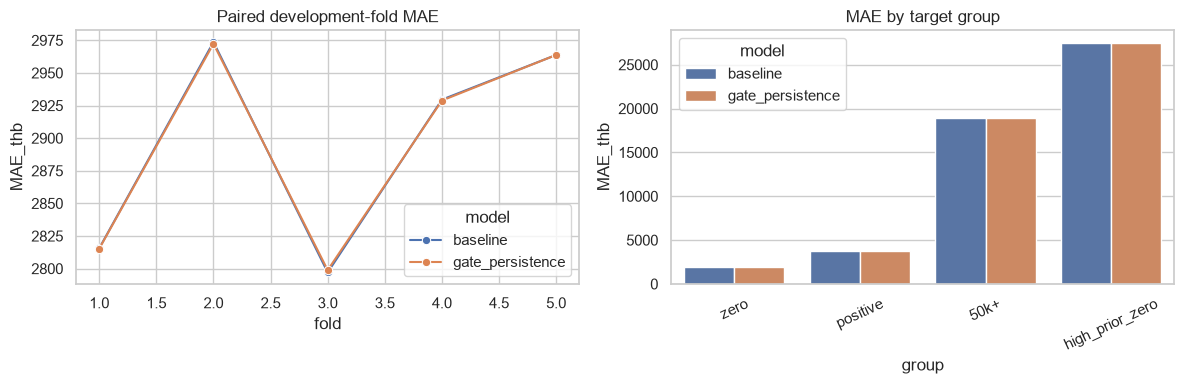

In [4]:
predictions={"baseline":baseline.baseline_prediction.to_numpy(),"gate_persistence":np.asarray(new_prediction)}
group_rows=[]
high_prior=dev.prev_month_spending.ge(dev.prev_month_spending.quantile(.8)).to_numpy()
groups={"all":np.ones(len(dev),dtype=bool),"zero":baseline.true.eq(0).to_numpy(),
        "positive":baseline.true.gt(0).to_numpy(),"50k+":baseline.true.ge(50000).to_numpy(),
        "high_prior_zero":baseline.true.eq(0).to_numpy()&high_prior}
for group,mask in groups.items():
    for name,pred in predictions.items():
        group_rows.append({"group":group,"model":name,"accounts":int(mask.sum()),
            "MAE_thb":mean_absolute_error(baseline.true.to_numpy()[mask],pred[mask]),
            "total_error":np.abs(baseline.true.to_numpy()[mask]-pred[mask]).sum()})
group_table=pd.DataFrame(group_rows)
display(group_table.pivot(index="group",columns="model",values="MAE_thb").round(2))
old_fp=(baseline.true.to_numpy()==0)&(baseline.old_probability.to_numpy()>=gate_threshold)
new_fp=(baseline.true.to_numpy()==0)&(new_probability>=gate_threshold)
display(pd.DataFrame({"gate":["old","new"],
    "false_nonzero_rows":[old_fp.sum(),new_fp.sum()],
    "high_prior_false_nonzero_rows":[(old_fp&high_prior).sum(),(new_fp&high_prior).sum()],
    "false_nonzero_final_error_thb":[np.abs(baseline.baseline_prediction.to_numpy()[old_fp]).sum(),
                                     np.abs(np.asarray(new_prediction)[new_fp]).sum()]}))
print("Old false-nonzero fixed:",int((old_fp&~new_fp).sum()),
      "new false-nonzero created:",int((~old_fp&new_fp).sum()))
fig,axes=plt.subplots(1,2,figsize=(12,4))
score_plot=pd.DataFrame({"fold":np.arange(1,6),"baseline":base_scores.to_numpy(),
                         "gate_persistence":new_scores.to_numpy()}).melt(id_vars="fold",var_name="model",value_name="MAE_thb")
sns.lineplot(data=score_plot,x="fold",y="MAE_thb",hue="model",marker="o",ax=axes[0])
axes[0].set(title="Paired development-fold MAE")
bar=group_table[group_table.group.isin(["zero","positive","50k+","high_prior_zero"])]
sns.barplot(data=bar,x="group",y="MAE_thb",hue="model",ax=axes[1])
axes[1].set(title="MAE by target group")
axes[1].tick_params(axis="x",labelrotation=25)
plt.tight_layout();plt.show()

## 4. Saved index and decision

Use the paired development folds as the main evidence. The reused 20% holdout can reveal a contradiction but is not fresh confirmation. If this targeted gate loses, do not expand the feature grid without another information clue.

In [5]:
index=read_evaluation_index(3)["evaluations"]
display(pd.DataFrame([{"model":name,"holdout_MAE_thb":index[name]["score"]}
    for name in ["t3_gate_blend_cv5_v2",NAME]]).sort_values("holdout_MAE_thb").round(2))

,model,holdout_MAE_thb
1,t3_gate_persistence_cv5_v4,2845.08
0,t3_gate_blend_cv5_v2,2845.10


## 5. Tail amount model

The persistence gate barely moved the OOF predictions. Test the other observed error source: replace only the positive-amount CatBoost with the same CatBoost MAE settings plus four tail features. Reuse the original OOF gate probability and continuous blend, with threshold and 80/20 weight fixed. The full model and its evaluation have a distinct name.

In [6]:
from catboost import CatBoostRegressor
AMOUNT_NAME="t3_amount_tail_cv5_v4"
AMOUNT_FEATURES=BASE+list(card["card"]["candidate_groups"]["tail"])
amount_model_path,amount_card_path,amount_eval_path=(
    SAVE/f"{AMOUNT_NAME}.joblib",SAVE/f"{AMOUNT_NAME}.json",SAVE/f"{AMOUNT_NAME}-evaluation.json")
def amount_regressor():
    numeric=[c for c in AMOUNT_FEATURES if c not in NOMINAL]
    preprocess=ColumnTransformer([
        ("numeric",SimpleImputer(strategy="median",add_indicator=True),numeric),
        ("nominal",Pipeline([
            ("impute",SimpleImputer(strategy="constant",fill_value=-1)),
            ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),NOMINAL),
    ],remainder="drop",sparse_threshold=0)
    return Pipeline([("preprocess",preprocess),
        ("regressor",CatBoostRegressor(loss_function="MAE",iterations=500,
            depth=6,learning_rate=.05,l2_leaf_reg=3.,random_seed=SEED,
            thread_count=4,verbose=False,allow_writing_files=False))])
amount_key={"dataset":DATA_NAME,"dataset_created_at":card["created_at"],
    "seed":SEED,"features":AMOUNT_FEATURES,"regressor":"CatBoost MAE 500x6 positive only",
    "outer":"same five stratified development folds"}
amount_parts=[]
for fold,(fit_pos,check_pos) in enumerate(splits,1):
    path=RESULTS/f"{AMOUNT_NAME}-fold{fold}.parquet"
    meta=RESULTS/f"{AMOUNT_NAME}-fold{fold}.json"
    if path.exists()!=meta.exists():raise RuntimeError(f"Incomplete amount fold {fold}")
    if path.exists():
        assert json.loads(meta.read_text(encoding="utf-8"))=={"key":amount_key,"fold":fold}
        part=pd.read_parquet(path)
        print("Loaded amount fold",fold)
    else:
        if amount_model_path.exists() or amount_card_path.exists() or amount_eval_path.exists():
            raise RuntimeError("Saved amount model has missing fold cache")
        model_amount=amount_regressor()
        fit=dev.iloc[fit_pos]
        check=dev.iloc[check_pos]
        positive=fit[TARGET]>0
        model_amount.fit(fit.loc[positive,AMOUNT_FEATURES],fit.loc[positive,TARGET])
        prediction=np.maximum(model_amount.predict(check[AMOUNT_FEATURES]),0)
        part=pd.DataFrame({"fold":fold,"row_pos":check_pos,
            "true":check[TARGET].to_numpy(),"positive_amount":prediction})
        part.to_parquet(path,index=False)
        meta.write_text(json.dumps({"key":amount_key,"fold":fold},indent=2),encoding="utf-8")
        print("Trained amount fold",fold)
    assert part.row_pos.tolist()==check_pos.tolist()
    assert np.array_equal(part.true,dev.iloc[check_pos][TARGET])
    amount_parts.append(part)
amount_oof=pd.concat(amount_parts,ignore_index=True).sort_values("row_pos").reset_index(drop=True)
assert np.array_equal(amount_oof.row_pos,np.arange(len(dev)))
new_amount=amount_oof.positive_amount.to_numpy()
amount_prediction=gate_weight*np.where(baseline.old_probability.to_numpy()>=gate_threshold,new_amount,0)+(1-gate_weight)*baseline.continuous.to_numpy()
amount_scores=fold_mae(amount_prediction)
if amount_model_path.exists() and amount_card_path.exists() and amount_eval_path.exists():
    amount_full=joblib.load(amount_model_path)
    amount_result=json.loads(amount_eval_path.read_text(encoding="utf-8"))
    assert amount_result["metric"]=="MAE_thb"
    print("Loaded saved amount model")
elif amount_model_path.exists() or amount_card_path.exists() or amount_eval_path.exists():
    raise RuntimeError("Incomplete saved amount model")
else:
    fitted_amount=amount_regressor()
    positive=dev[TARGET]>0
    fitted_amount.fit(dev.loc[positive,AMOUNT_FEATURES],dev.loc[positive,TARGET])
    amount_full=WeightedPair(PositiveGate(old_gate.occurrence_model,fitted_amount,gate_threshold),
                             old_blend,gate_weight)
    pred=amount_full.predict(valid.drop(columns=[ID,TARGET]))
    save_model(task=3,name=AMOUNT_NAME,model=amount_full,data_name=DATA_NAME,
        card={"idea":"Four tail features in positive-amount CatBoost only",
              "source_model":"t3_gate_blend_cv5_v2",
              "new_features":list(card["card"]["candidate_groups"]["tail"]),
              "unchanged_components":["occurrence CatBoost","continuous 40/60 blend"],
              "gate_threshold":gate_threshold,"gate_weight":gate_weight,
              "development_cv_mean_MAE_thb":float(amount_scores.mean()),"seed":SEED,
              "metric_note":"MAE THB; NMAE denominator unavailable"})
    amount_result=evaluate_model(task=3,name=AMOUNT_NAME,
        score=mean_absolute_error(valid[TARGET],pred),metric_name="MAE_thb",
        higher_is_better=False,card={"split":"original stratified 20% holdout; reused",
            "development_fold_MAE_thb":amount_scores.to_dict(),"seed":SEED})
    print("Saved amount model and evaluation")
amount_holdout=mean_absolute_error(valid[TARGET],amount_full.predict(valid.drop(columns=[ID,TARGET])))
assert abs(amount_holdout-amount_result["score"])<.05
display(pd.DataFrame({"baseline":base_scores,"amount_tail":amount_scores,
                      "delta":amount_scores-base_scores}).round(2))
print("Amount model mean CV:",round(amount_scores.mean(),2),
      "delta:",round(amount_scores.mean()-base_scores.mean(),2),
      "holdout:",round(amount_holdout,2))

Loaded amount fold 1
Loaded amount fold 2
Loaded amount fold 3
Loaded amount fold 4
Loaded amount fold 5
Loaded saved amount model


,baseline,amount_tail,delta
fold,,,
1,2815.58,2830.99,15.41
2,2973.69,2979.22,5.53
3,2797.07,2815.51,18.44
4,2929.51,2928.46,-1.05
5,2963.76,2996.59,32.83


Amount model mean CV: 2910.15 delta: 14.23 holdout: 2852.17


## 6. Compare both targeted changes

The table holds the same OOF rows and fixed mixture. Break out zero, positive, 50k+, and high-prior-spend zero targets. A small gain that changes sign across folds does not justify replacing the existing mixture.

In [7]:
comparison=pd.DataFrame({"baseline":base_scores,"gate_persistence":new_scores,
                         "amount_tail":amount_scores})
display(comparison.round(2))
display(comparison.agg(["mean","std"]).round(2))
predictions={"baseline":baseline.baseline_prediction.to_numpy(),
             "gate_persistence":np.asarray(new_prediction),
             "amount_tail":np.asarray(amount_prediction)}
rows=[]
for group,mask in groups.items():
    for name,pred in predictions.items():
        rows.append({"group":group,"model":name,"accounts":int(mask.sum()),
            "MAE_thb":mean_absolute_error(baseline.true.to_numpy()[mask],pred[mask]),
            "total_error":np.abs(baseline.true.to_numpy()[mask]-pred[mask]).sum()})
display(pd.DataFrame(rows).pivot(index="group",columns="model",values="MAE_thb").round(2))
index=read_evaluation_index(3)["evaluations"]
display(pd.DataFrame([{"model":name,"holdout_MAE_thb":index[name]["score"]}
    for name in ["t3_gate_blend_cv5_v2",NAME,AMOUNT_NAME]]).sort_values("holdout_MAE_thb").round(2))

,baseline,gate_persistence,amount_tail
fold,,,
1,2815.58,2815.27,2830.99
2,2973.69,2972.36,2979.22
3,2797.07,2798.82,2815.51
4,2929.51,2928.82,2928.46
5,2963.76,2963.76,2996.59


,baseline,gate_persistence,amount_tail
mean,2895.92,2895.81,2910.15
std,83.67,82.85,83.37


model,amount_tail,baseline,gate_persistence
group,,,
50k+,19040.98,18923.14,18923.14
all,2910.15,2895.92,2895.81
high_prior_zero,27561.32,27525.97,27523.77
positive,3818.74,3793.93,3793.92
zero,1930.72,1927.89,1927.66


,model,holdout_MAE_thb
1,t3_gate_persistence_cv5_v4,2845.08
0,t3_gate_blend_cv5_v2,2845.10
2,t3_amount_tail_cv5_v4,2852.17


### Round decision

Read paired development folds first and the reused holdout second. The zero-aware and tail errors remain the next information targets only if a concrete new signal is available; further arbitrary ratios or global amount scaling have little support from this round.

## 7. Cost-weighted gate for high-prior-spend lapses

The feature ratios barely changed the gate, while high-prior-spend zero targets remain costly. Keep the original 48 predictors and CatBoost classifier settings; within each fold's **training rows only**, give weight 3 to zero-target accounts above that fold's 80th percentile of previous-month spending. All other rows have weight 1. This is one prespecified cost-sensitive check, not a weight grid. Reuse the original positive-amount and continuous-blend OOF outputs and fixed 0.50/80:20 decision rule.

In [8]:
WEIGHTED_NAME="t3_weighted_gate_cv5_v4"
WEIGHTED_FEATURES=BASE
weighted_model_path,weighted_card_path,weighted_eval_path=(
    SAVE/f"{WEIGHTED_NAME}.joblib",SAVE/f"{WEIGHTED_NAME}.json",
    SAVE/f"{WEIGHTED_NAME}-evaluation.json")
def weighted_classifier():
    numeric=[c for c in WEIGHTED_FEATURES if c not in NOMINAL]
    preprocess=ColumnTransformer([
        ("numeric",SimpleImputer(strategy="median",add_indicator=True),numeric),
        ("nominal",Pipeline([
            ("impute",SimpleImputer(strategy="constant",fill_value=-1)),
            ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),NOMINAL),
    ],remainder="drop",sparse_threshold=0)
    return Pipeline([("preprocess",preprocess),
        ("classifier",CatBoostClassifier(loss_function="Logloss",iterations=350,
            depth=6,learning_rate=.05,l2_leaf_reg=3.,random_seed=SEED,
            thread_count=4,verbose=False,allow_writing_files=False))])
def training_weights(fit):
    cutoff=float(fit.prev_month_spending.quantile(.8))
    expensive_zero=fit[TARGET].eq(0)&fit.prev_month_spending.ge(cutoff)
    return np.where(expensive_zero,3.0,1.0),cutoff
weighted_key={"dataset":DATA_NAME,"dataset_created_at":card["created_at"],
    "seed":SEED,"features":WEIGHTED_FEATURES,"classifier":"CatBoost Logloss 350x6",
    "weight_rule":"3x for zero target and previous spending >= training q80",
    "outer":"same five stratified development folds"}
weighted_parts=[]
for fold,(fit_pos,check_pos) in enumerate(splits,1):
    path=RESULTS/f"{WEIGHTED_NAME}-fold{fold}.parquet"
    meta=RESULTS/f"{WEIGHTED_NAME}-fold{fold}.json"
    if path.exists()!=meta.exists():raise RuntimeError(f"Incomplete weighted fold {fold}")
    if path.exists():
        assert json.loads(meta.read_text(encoding="utf-8"))=={"key":weighted_key,"fold":fold}
        part=pd.read_parquet(path)
        print("Loaded weighted fold",fold)
    else:
        if weighted_model_path.exists() or weighted_card_path.exists() or weighted_eval_path.exists():
            raise RuntimeError("Saved weighted model has missing fold cache")
        fit=dev.iloc[fit_pos];check=dev.iloc[check_pos]
        weights,cutoff=training_weights(fit)
        model_weighted=weighted_classifier()
        model_weighted.fit(fit[WEIGHTED_FEATURES],(fit[TARGET]>0).astype(int),
                           classifier__sample_weight=weights)
        probability=model_weighted.predict_proba(check[WEIGHTED_FEATURES])[:,1]
        part=pd.DataFrame({"fold":fold,"row_pos":check_pos,
            "true":check[TARGET].to_numpy(),"probability":probability,
            "training_q80":cutoff})
        part.to_parquet(path,index=False)
        meta.write_text(json.dumps({"key":weighted_key,"fold":fold},indent=2),encoding="utf-8")
        print("Trained weighted fold",fold)
    assert part.row_pos.tolist()==check_pos.tolist()
    assert np.array_equal(part.true,dev.iloc[check_pos][TARGET])
    weighted_parts.append(part)
weighted_oof=pd.concat(weighted_parts,ignore_index=True).sort_values("row_pos").reset_index(drop=True)
assert np.array_equal(weighted_oof.row_pos,np.arange(len(dev)))
weighted_probability=weighted_oof.probability.to_numpy()
weighted_prediction=gate_weight*np.where(weighted_probability>=gate_threshold,
    baseline.old_amount.to_numpy(),0)+(1-gate_weight)*baseline.continuous.to_numpy()
weighted_scores=fold_mae(weighted_prediction)
if weighted_model_path.exists() and weighted_card_path.exists() and weighted_eval_path.exists():
    weighted_full=joblib.load(weighted_model_path)
    weighted_result=json.loads(weighted_eval_path.read_text(encoding="utf-8"))
    assert weighted_result["metric"]=="MAE_thb"
    print("Loaded saved weighted model")
elif weighted_model_path.exists() or weighted_card_path.exists() or weighted_eval_path.exists():
    raise RuntimeError("Incomplete saved weighted model")
else:
    full_weights,full_cutoff=training_weights(dev)
    classifier_full=weighted_classifier()
    classifier_full.fit(dev[WEIGHTED_FEATURES],(dev[TARGET]>0).astype(int),
                        classifier__sample_weight=full_weights)
    weighted_full=WeightedPair(PositiveGate(classifier_full,old_gate.positive_amount_model,
                                            gate_threshold),old_blend,gate_weight)
    pred=weighted_full.predict(valid.drop(columns=[ID,TARGET]))
    save_model(task=3,name=WEIGHTED_NAME,model=weighted_full,data_name=DATA_NAME,
        card={"idea":"Cost-weighted occurrence gate for high-prior-spend zero targets",
              "source_model":"t3_gate_blend_cv5_v2","features":WEIGHTED_FEATURES,
              "weight_rule":"3x for zero target and previous spending >= training q80",
              "full_development_q80":full_cutoff,"gate_threshold":gate_threshold,
              "gate_weight":gate_weight,"development_cv_mean_MAE_thb":float(weighted_scores.mean()),
              "seed":SEED,"metric_note":"MAE THB; NMAE denominator unavailable"})
    weighted_result=evaluate_model(task=3,name=WEIGHTED_NAME,
        score=mean_absolute_error(valid[TARGET],pred),metric_name="MAE_thb",
        higher_is_better=False,card={"split":"original stratified 20% holdout; reused",
            "development_fold_MAE_thb":weighted_scores.to_dict(),"seed":SEED})
    print("Saved weighted model and evaluation")
weighted_holdout=mean_absolute_error(valid[TARGET],
    weighted_full.predict(valid.drop(columns=[ID,TARGET])))
assert abs(weighted_holdout-weighted_result["score"])<.05
display(pd.DataFrame({"baseline":base_scores,"weighted_gate":weighted_scores,
                      "delta":weighted_scores-base_scores}).round(2))
print("Weighted gate mean CV:",round(weighted_scores.mean(),2),
      "delta:",round(weighted_scores.mean()-base_scores.mean(),2),
      "holdout:",round(weighted_holdout,2))

Trained weighted fold 1


Trained weighted fold 2


Trained weighted fold 3


Trained weighted fold 4


Trained weighted fold 5


Saved weighted model and evaluation


,baseline,weighted_gate,delta
fold,,,
1,2815.58,2841.93,26.35
2,2973.69,3006.50,32.80
3,2797.07,2823.83,26.76
4,2929.51,2962.25,32.74
5,2963.76,2997.59,33.83


Weighted gate mean CV: 2926.42 delta: 30.5 holdout: 2876.51


## 8. Inspect the weighted-gate tradeoff

Quantify false-nonzero rows removed, positive-spender rows lost, and MAE in the costly groups. A lower false-nonzero count can still worsen MAE if the gate suppresses valuable positive predictions.

In [9]:
old_nonzero=baseline.old_probability.to_numpy()>=gate_threshold
weighted_nonzero=weighted_probability>=gate_threshold
truth_positive=baseline.true.to_numpy()>0
tradeoff=pd.DataFrame([
    {"gate":"old","false_nonzero":int((~truth_positive&old_nonzero).sum()),
     "false_zero":int((truth_positive&~old_nonzero).sum())},
    {"gate":"weighted","false_nonzero":int((~truth_positive&weighted_nonzero).sum()),
     "false_zero":int((truth_positive&~weighted_nonzero).sum())},
])
display(tradeoff)
comparison=pd.DataFrame({"baseline":base_scores,"persistence":new_scores,
                         "amount_tail":amount_scores,"weighted_gate":weighted_scores})
display(comparison.round(2))
display(comparison.agg(["mean","std"]).round(2))
predictions={"baseline":baseline.baseline_prediction.to_numpy(),
             "weighted_gate":np.asarray(weighted_prediction)}
rows=[]
for group,mask in groups.items():
    for name,pred in predictions.items():
        rows.append({"group":group,"model":name,"accounts":int(mask.sum()),
            "MAE_thb":mean_absolute_error(baseline.true.to_numpy()[mask],pred[mask])})
display(pd.DataFrame(rows).pivot(index="group",columns="model",values="MAE_thb").round(2))
index=read_evaluation_index(3)["evaluations"]
display(pd.DataFrame([{"model":name,"holdout_MAE_thb":index[name]["score"]}
    for name in ["t3_gate_blend_cv5_v2",NAME,AMOUNT_NAME,WEIGHTED_NAME]])
    .sort_values("holdout_MAE_thb").round(2))

,gate,false_nonzero,false_zero
0,old,10849,12676
1,weighted,9993,14352


,baseline,persistence,amount_tail,weighted_gate
fold,,,,
1,2815.58,2815.27,2830.99,2841.93
2,2973.69,2972.36,2979.22,3006.50
3,2797.07,2798.82,2815.51,2823.83
4,2929.51,2928.82,2928.46,2962.25
5,2963.76,2963.76,2996.59,2997.59


,baseline,persistence,amount_tail,weighted_gate
mean,2895.92,2895.81,2910.15,2926.42
std,83.67,82.85,83.37,87.21


model,baseline,weighted_gate
group,,
50k+,18923.14,18923.14
all,2895.92,2926.42
high_prior_zero,27525.97,26020.89
positive,3793.93,3925.12
zero,1927.89,1849.84


,model,holdout_MAE_thb
1,t3_gate_persistence_cv5_v4,2845.08
0,t3_gate_blend_cv5_v2,2845.10
2,t3_amount_tail_cv5_v4,2852.17
3,t3_weighted_gate_cv5_v4,2876.51


### Final decision for this round

The cost-weighted gate is a single targeted intervention informed by the OOF error audit. Use paired fold MAE and the zero/positive/tail tradeoff to decide whether further Task 3 work is justified. The holdout remains reused and the official NMAE denominator remains unknown.